# Assignment 20 – Word2Vec Text Embeddings

**Dataset:** 40-sentence custom educational corpus  
**Model:** Word2Vec (CBOW and Skip-Gram)  
**Embedding size:** 100

This notebook follows Tasks 1–10 from the assignment brief. Tasks 1–4 are conceptual explanations in Markdown, and Tasks 5–9 contain the practical implementation.

## Task 1 – Understanding Word Embeddings

### What are word embeddings?
A word embedding is a numerical vector that represents a word. The vector is learned from the way the word is used with other words.

### Why One-Hot Encoding and BOW fail to capture semantics
One-hot encoding gives every word its own position, but it does not say that *good* and *great* are related. The vectors are also very sparse.

Bag of Words counts words in documents. It is useful for frequency, but it ignores most word order and context and produces large sparse vectors. Two words can be related in meaning but still be separate BOW columns.

### How embeddings solve this
Word embeddings are dense vectors learned from context. Words that occur in similar contexts can have similar vectors, so the vector space can capture useful relationships and similarities.

## Task 2 – Word2Vec Overview

Word2Vec learns word vectors by using nearby words as training information. The model repeatedly sees words and their contexts and adjusts its weights to make better predictions.

**Vocabulary:** the words kept by the trained model.

**Context window:** the number of nearby words considered around a target word. This notebook uses `window=5`.

**Embedding dimension:** the number of numbers in one word vector. This notebook uses `vector_size=100`.

For example, in `the movie was really good`, the nearby words provide context that helps the model learn the representation of `movie`.

## Task 3 – Types of Word2Vec

### CBOW
CBOW (Continuous Bag of Words) predicts the target word from surrounding context.

Example: `the movie was ___ good`

CBOW is usually efficient and works well when there is a lot of common-word training data.

### Skip-Gram
Skip-Gram predicts nearby context words from a target word.

Example: `movie` → `the`, `was`, `good`

Skip-Gram can be useful for learning representations of less frequent words and detailed word relationships.

**When to use:** CBOW is a good choice when speed is important; Skip-Gram is useful when rare-word representations and detailed context are more important.

## Task 4 – Neural Network Intuition Behind Word2Vec

A simplified Word2Vec network can be viewed as having:

1. **Input layer** – represents the input word/context.
2. **Hidden layer** – contains learnable weights and acts as the dense representation.
3. **Output layer** – predicts a word from the vocabulary.

During training, prediction errors cause the weights to be updated. After training, the learned hidden-layer weight rows are used as word embeddings. Therefore, the embedding is learned from context rather than manually assigned.

## Task 5 – Prepare Text for Word2Vec

In [1]:
import pandas as pd
import re

data = pd.read_csv("data/custom_word2vec_corpus.csv")

sentences = []
for text in data["text"]:
    tokens = re.findall(r"[a-z]+", text.lower())
    sentences.append(tokens)

print("Number of sentences:", len(sentences))
print("First 20 tokenized sentences:")
for s in sentences[:20]:
    print(s)

Number of sentences: 43
First 20 tokenized sentences:
['the', 'king', 'ruled', 'the', 'kingdom', 'with', 'wisdom', 'and', 'courage']
['the', 'queen', 'ruled', 'the', 'kingdom', 'with', 'wisdom', 'and', 'kindness']
['the', 'king', 'wore', 'a', 'royal', 'crown', 'during', 'the', 'ceremony']
['the', 'queen', 'wore', 'a', 'royal', 'crown', 'during', 'the', 'ceremony']
['the', 'prince', 'learned', 'leadership', 'from', 'the', 'king']
['the', 'princess', 'learned', 'leadership', 'from', 'the', 'queen']
['the', 'king', 'and', 'queen', 'visited', 'the', 'palace', 'garden']
['the', 'prince', 'and', 'princess', 'visited', 'the', 'royal', 'palace']
['a', 'king', 'is', 'a', 'male', 'royal', 'leader']
['a', 'queen', 'is', 'a', 'female', 'royal', 'leader']
['a', 'man', 'can', 'become', 'a', 'king', 'in', 'a', 'royal', 'family']
['a', 'woman', 'can', 'become', 'a', 'queen', 'in', 'a', 'royal', 'family']
['the', 'man', 'and', 'woman', 'visited', 'the', 'royal', 'palace']
['the', 'man', 'became', 'king

## Task 6 – Train CBOW Word2Vec

In [2]:
from gensim.models import Word2Vec

# The small corpus is repeated to give the model more training examples.
training_sentences = sentences * 30

cbow = Word2Vec(
    sentences=training_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=1,
    sg=0,
    seed=42,
    epochs=50
)

print("CBOW vocabulary size:", len(cbow.wv))
print("Vector size:", cbow.wv.vector_size)
print("Vector for 'movie' (first 10 values):")
print(cbow.wv["movie"][:10])
print("Similar words to 'movie':")
print(cbow.wv.most_similar("movie", topn=5))

CBOW vocabulary size: 93
Vector size: 100
Vector for 'movie' (first 10 values):
[-0.09651935  0.16572644  0.6706862   0.17972985 -0.21136591  0.20762356
 -0.36522344  0.05741724  0.3958472   0.37315977]
Similar words to 'movie':
[('film', 0.5887680053710938), ('audience', 0.5313144326210022), ('make', 0.5295353531837463), ('interesting', 0.5229018330574036), ('characters', 0.5052310228347778)]


## Task 7 – Train Skip-Gram and Compare

In [3]:
skipgram = Word2Vec(
    sentences=training_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=1,
    sg=1,
    seed=42,
    epochs=50
)

print("Skip-Gram vocabulary size:", len(skipgram.wv))
print("Vector size:", skipgram.wv.vector_size)

print("\nCBOW similar words to movie:")
print(cbow.wv.most_similar("movie", topn=5))

print("\nSkip-Gram similar words to movie:")
print(skipgram.wv.most_similar("movie", topn=5))

print("\nTraining setup:")
print("CBOW uses sg=0")
print("Skip-Gram uses sg=1")

Skip-Gram vocabulary size: 93
Vector size: 100

CBOW similar words to movie:
[('film', 0.5887680053710938), ('audience', 0.5313144326210022), ('make', 0.5295353531837463), ('interesting', 0.5229018330574036), ('characters', 0.5052310228347778)]

Skip-Gram similar words to movie:
[('film', 0.5504211187362671), ('audience', 0.5450742244720459), ('story', 0.5073996782302856), ('enjoyed', 0.5005113482475281), ('actor', 0.47523200511932373)]

Training setup:
CBOW uses sg=0
Skip-Gram uses sg=1


## Task 8 – Word Similarity & Vector Operations

1. Find words similar to a selected word using `most_similar()`.
2. Test the vector relationship:

`king - man + woman`

3. Compare three pairs:
- good – great
- movie – film
- king – queen

The analogy is a demonstration of how vector directions can encode relationships. It is not guaranteed to be exact on every dataset.

In [4]:
pairs = [("good","great"), ("movie","film"), ("king","queen")]

print("CBOW similarity:")
for a,b in pairs:
    print(a, "-", b, "=", round(cbow.wv.similarity(a,b),4))

print("\nSkip-Gram similarity:")
for a,b in pairs:
    print(a, "-", b, "=", round(skipgram.wv.similarity(a,b),4))

print("\nCBOW: king - man + woman")
print(cbow.wv.most_similar(positive=["king","woman"], negative=["man"], topn=5))

print("\nSkip-Gram: king - man + woman")
print(skipgram.wv.most_similar(positive=["king","woman"], negative=["man"], topn=5))

CBOW similarity:
good - great = 0.321
movie - film = 0.5888
king - queen = 0.9406

Skip-Gram similarity:
good - great = 0.4137
movie - film = 0.5504
king - queen = 0.688

CBOW: king - man + woman
[('queen', 0.8111465573310852), ('princess', 0.4688794016838074), ('prince', 0.3611115515232086), ('during', 0.354320228099823), ('royal', 0.31687426567077637)]

Skip-Gram: king - man + woman
[('princess', 0.5007455945014954), ('queen', 0.37662264704704285), ('during', 0.3736782670021057), ('kindness', 0.371645450592041), ('times', 0.3602325916290283)]


## Task 9 – Visualizing Word Embeddings

A 100-dimensional vector cannot be plotted directly in 2D.

**PCA** reduces the vectors to two dimensions while preserving directions that explain large variance.

**t-SNE** creates a 2D map that tries to preserve local neighborhoods.

In the plots, related royal words and related movie/review words can form groups. The clusters are observations from this small custom corpus, not proof that the model understands language perfectly.

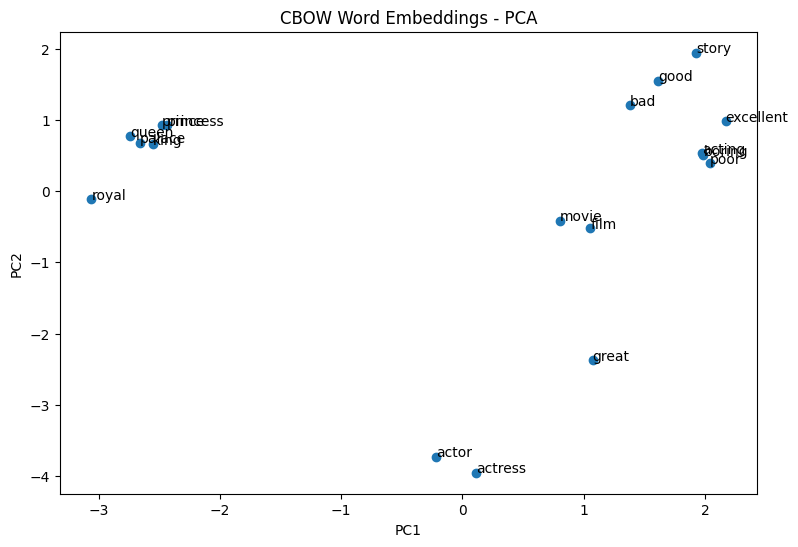

PCA explained variance: [0.294681   0.20156734]


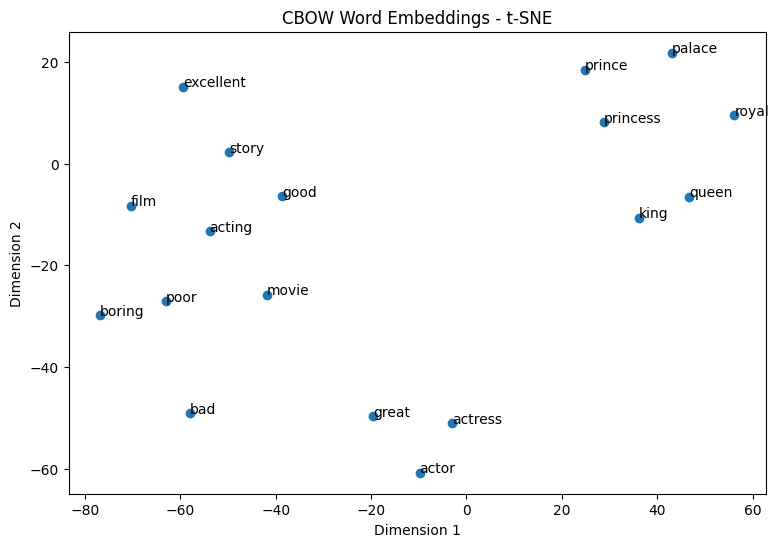

Number of words visualized: 18


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

plot_words = [
    "king","queen","prince","princess","royal","palace",
    "movie","film","story","acting","actor","actress",
    "good","great","bad","poor","excellent","boring"
]
vectors = np.array([cbow.wv[w] for w in plot_words])

pca = PCA(n_components=2, random_state=42)
pca_points = pca.fit_transform(vectors)

plt.figure(figsize=(9,6))
plt.scatter(pca_points[:,0], pca_points[:,1])
for i,word in enumerate(plot_words):
    plt.annotate(word,(pca_points[i,0],pca_points[i,1]))
plt.title("CBOW Word Embeddings - PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

print("PCA explained variance:", pca.explained_variance_ratio_)

tsne = TSNE(n_components=2, perplexity=6, init="random",
            learning_rate="auto", random_state=42)
tsne_points = tsne.fit_transform(vectors)

plt.figure(figsize=(9,6))
plt.scatter(tsne_points[:,0], tsne_points[:,1])
for i,word in enumerate(plot_words):
    plt.annotate(word,(tsne_points[i,0],tsne_points[i,1]))
plt.title("CBOW Word Embeddings - t-SNE")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.show()

print("Number of words visualized:", len(plot_words))

## Task 10 – Observations & Limitations

### CBOW vs Skip-Gram in practice
CBOW predicts a target from context and is generally faster. Skip-Gram predicts context from a target and can be useful for less frequent words. In this run both models learned related neighborhoods, but their nearest-word ordering was not identical.

### Advantages of Word2Vec over TF-IDF
Word2Vec learns dense word vectors from context and can represent word similarity and relationships. TF-IDF mainly describes how important a word is to a document based on frequency. Word2Vec is therefore better when word-level semantic relationships are important.

### Limitations of Word2Vec
- One word normally has one fixed vector even when it has multiple meanings.
- It needs enough representative training text.
- It cannot naturally represent unseen words.
- Results depend on the training corpus.
- Biases in the training text can appear in the learned vectors.

### Why context matters in modern NLP
A word can change meaning depending on surrounding words. Word2Vec gives a mostly fixed representation for each word, while modern transformer models use attention to build context-dependent representations. This is one reason context is central to modern NLP.

## Final Output

In [6]:
# Save results for inspection
similarity_results = []
for a,b in pairs:
    similarity_results.append({
        "pair": f"{a} - {b}",
        "CBOW": cbow.wv.similarity(a,b),
        "Skip-Gram": skipgram.wv.similarity(a,b)
    })
pd.DataFrame(similarity_results).to_csv("similarity_results.csv", index=False)

analogy_results = []
for model_name, model in [("CBOW",cbow),("Skip-Gram",skipgram)]:
    result = model.wv.most_similar(
        positive=["king","woman"],
        negative=["man"],
        topn=5
    )
    analogy_results.append({"model":model_name,"top_results":str(result)})
pd.DataFrame(analogy_results).to_csv("analogy_results.csv", index=False)

print("Saved similarity_results.csv")
print("Saved analogy_results.csv")
print("All 10 tasks are included.")

Saved similarity_results.csv
Saved analogy_results.csv
All 10 tasks are included.
